<a href="https://colab.research.google.com/github/D2718281828nis/ML-machinelearning_fundamentals/blob/main/GNN%20Graph-EVT-agent%20digital%20twin%20tonsillopharyngitis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Цифровой двойник хронического тонзиллофарингита: EVT + граф + GNN/GAT

**Контекст.** Статья «Цифровое моделирование процесса хронического тонзиллофарингита (ХТФ) с субфебрилитетом и
лимфаденопатией, ассоциированных с герпесвирусной инфекцией»: 150 пациентов, три схемы лечения
(A — валацикловир, B — аминодигидрофталазиндион натрия, C — их комбинация), ПЦР на герпесвирусы
в 1-е сутки и через 6 месяцев, температура и клинические проявления. Данные — `data_HTF.csv`.

**Инструмент.** Библиотека [Graph-EVT-agent](https://github.com/D2718281828nis/Graph-EVT-agent):
EVT (POT/GPD) отвечает «кто экстремален?», граф — «как связаны узлы?», GNN/GAT — «какой узел — источник?»,
агенты Mistral — объясняют численный результат, но не меняют его.

| Часть | Вопрос | Метод |
|---|---|---|
| 0 | Что на самом деле лежит в `source`/`target`? | расшифровка битовой маски вирусов |
| 1 | У каких пациентов состояние после лечения экстремально? («терапевтический побег») | `graph_evt_agent.evt.detect` (робастная нормировка + GPD-порог) |
| 2 | Какие вирусы встречаются вместе? | граф ко-инфекции + перестановочный тест |
| 3 | **Какой вирус сохранится через 6 месяцев?** (вариант A) | `GraphProcessModel` (GNN и GAT) из Graph-EVT-agent |
| 4 | **Будет ли ПЦР отрицательной и какая схема лучше?** (вариант B) | GCN/GAT из PyTorch Geometric + сценарий «что если» |
| 5 | Понятный отчёт | команда агентов на `MistralClient` (опционально) |

> ⚠️ Учебный пример. Группы лечения не рандомизированы внутри этого файла, выборка мала (n = 150),
> рёбра графа — ассоциации, а не причинность. Результаты — гипотезы для врача, а не назначения.

## Установка

Graph-EVT-agent ставится из GitHub. PyTorch в Colab уже есть; `torch_geometric` доустанавливается при необходимости.

In [1]:
import importlib.util
import subprocess
import sys


def ensure(module: str, pip_name: str) -> None:
    if importlib.util.find_spec(module) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pip_name])


ensure("graph_evt_agent", "git+https://github.com/D2718281828nis/Graph-EVT-agent.git")
ensure("torch_geometric", "torch_geometric")
ensure("networkx", "networkx")
ensure("sklearn", "scikit-learn")

In [2]:
import json
import os
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F

from graph_evt_agent import EVTConfig, GraphEpisode, GraphLearningConfig, GraphProcessModel
from graph_evt_agent.evt import detect
from graph_evt_agent.training import ranking_metrics, split_episodes
from graph_evt_agent import visualization as viz

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", message="IProgress not found")
pd.set_option("display.precision", 3)

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

# Цвета: группы лечения и «1 сутки / 6 месяцев» — фиксированные категориальные слоты.
GROUP_COLORS = {"A": "#2a78d6", "B": "#eb6834", "C": "#1baf7a"}
GROUP_NAMES = {"A": "A: валацикловир", "B": "B: аминодигидрофталазиндион Na", "C": "C: комбинация"}
TIME_COLORS = {"1 сутки": "#2a78d6", "6 месяцев": "#eb6834"}
MUTED, NEUTRAL, ALARM = "#52514e", "#b8b7b1", "#e34948"


def style(ax):
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.grid(True, axis="y", color="#e6e5e0", linewidth=0.6)
    ax.set_axisbelow(True)
    ax.tick_params(colors=MUTED)

## Часть 0. Данные и расшифровка кодов

`data_HTF.csv`: `;` — разделитель, `,` — десятичная запятая.

| Столбец | Смысл (по статье) |
|---|---|
| `source` | результат ПЦР в 1-е сутки (код набора вирусов) |
| `target` | результат ПЦР через 6 месяцев (код набора вирусов) |
| `edge_weights` | агрегированные клинические проявления |
| `nf1` | агрегированный показатель клинических проявлений |
| `nf2`, `nf3` | температура на 14-й день и через 6 месяцев |
| `class` | группа лечения: 1 = A, 2 = B, 3 = C |

In [3]:
LOCAL = Path("test_datasets/data_HTF.csv")
URL = ("https://raw.githubusercontent.com/D2718281828nis/ML-machinelearning_fundamentals/"
       "main/test_datasets/data_HTF.csv")
df = pd.read_csv(LOCAL if LOCAL.exists() else URL, sep=";", decimal=",", encoding="utf-8-sig")
print(df.shape)
df.head()

(150, 7)


,source,target,edge_weights,nf1,nf2,nf3,class
0,3,1,3,11,37.3,37.1,1
1,7,1,2,10,37.8,37.7,1
2,2,1,3,11,37.1,37.2,1
3,3,0,2,10,37.2,37.3,1
4,2,1,0,10,37.7,37.0,1


Коды `source`/`target` — **битовая маска**: каждому вирусу соответствует степень двойки, а код — их сумма.
Это следует из подписей узлов в ноутбуке `GNN simple example Graph Convolution Network.ipynb`
(`3 = EBV, HHV-6`, `7 = CMV, EBV, HHV-6`, `27 = HSV-1, HSV-2, EBV, HHV-6` …):

| Вирус | HHV-6 | EBV | CMV | HSV-2 | HSV-1 |
|---|---|---|---|---|---|
| Бит | 1 | 2 | 4 | 8 | 16 |

Раскладываем каждый код на 5 бинарных признаков «вирус обнаружен» — в 1-е сутки и через 6 месяцев.

In [4]:
VIRUSES = ["HHV-6", "EBV", "CMV", "HSV-2", "HSV-1"]
BITS = [1, 2, 4, 8, 16]


def decode(code: int) -> list[str]:
    return [virus for virus, bit in zip(VIRUSES, BITS) if code & bit]


def state_name(code: int) -> str:
    return ", ".join(decode(code)) or "negative"


# Проверка расшифровки на подписях из исходного ноутбука
assert state_name(3) == "HHV-6, EBV" and state_name(7) == "HHV-6, EBV, CMV"
assert state_name(27) == "HHV-6, EBV, HSV-2, HSV-1"

D1 = np.array([[bool(c & b) for b in BITS] for c in df["source"]], dtype=float)  # 1-е сутки
M6 = np.array([[bool(c & b) for b in BITS] for c in df["target"]], dtype=float)  # 6 месяцев

df["group"] = df["class"].map({1: "A", 2: "B", 3: "C"})
df["state_d1"] = df["source"].map(state_name)
df["state_6m"] = df["target"].map(state_name)
df["n_viruses_d1"] = D1.sum(axis=1)
df["n_viruses_6m"] = M6.sum(axis=1)
df["pcr_negative_6m"] = df["target"] == 0

prevalence = pd.DataFrame({"1 сутки": D1.sum(axis=0), "6 месяцев": M6.sum(axis=0)},
                          index=VIRUSES).astype(int)
prevalence["сохранился (из выявленных в 1 сутки)"] = (D1 * M6).sum(axis=0).astype(int)
prevalence["впервые выявлен к 6 мес."] = ((1 - D1) * M6).sum(axis=0).astype(int)
prevalence

,1 сутки,6 месяцев,сохранился (из выявленных в 1 сутки),впервые выявлен к 6 мес.
HHV-6,87,49,38,11
EBV,138,22,22,0
CMV,23,2,2,0
HSV-2,19,1,1,0
HSV-1,22,1,1,0


In [5]:
by_group = df.groupby("group").agg(
    пациентов=("source", "size"),
    доля_ПЦР_отр_6мес=("pcr_negative_6m", "mean"),
    вирусов_в_1_сутки=("n_viruses_d1", "mean"),
    вирусов_через_6мес=("n_viruses_6m", "mean"),
    t_14_день=("nf2", "mean"),
    t_6_мес=("nf3", "mean"),
    nf1=("nf1", "mean"),
)
by_group

,пациентов,доля_ПЦР_отр_6мес,вирусов_в_1_сутки,вирусов_через_6мес,t_14_день,t_6_мес,nf1
group,,,,,,,
A,50,0.640,1.940,0.420,36.742,36.718,4.960
B,48,0.292,2.104,0.812,36.988,36.927,9.458
C,52,0.712,1.750,0.288,36.663,36.635,2.942


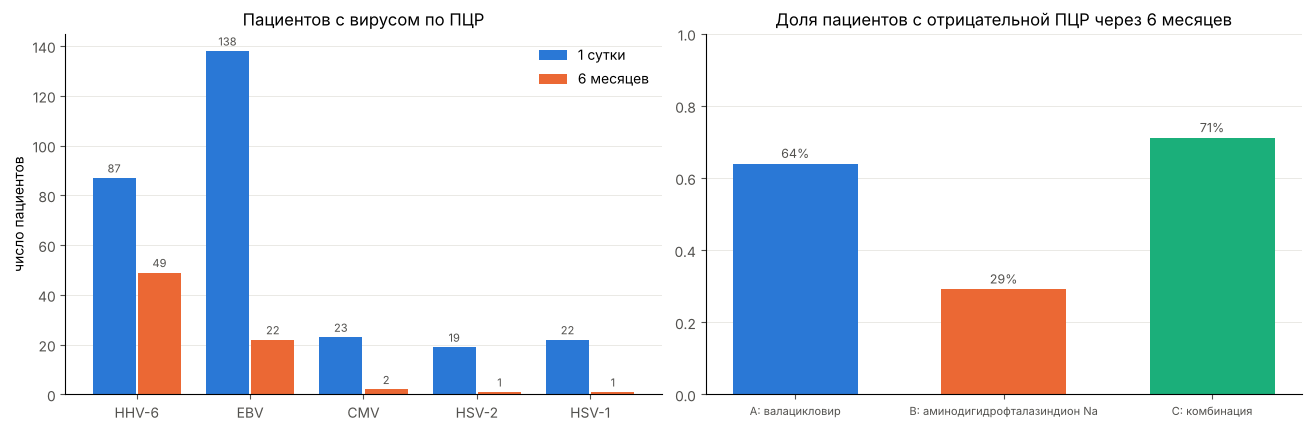

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), constrained_layout=True)
ax = axes[0]
x = np.arange(len(VIRUSES))
for offset, column in ((-0.2, "1 сутки"), (0.2, "6 месяцев")):
    bars = ax.bar(x + offset, prevalence[column], 0.38, color=TIME_COLORS[column], label=column)
    ax.bar_label(bars, fontsize=8, color=MUTED, padding=2)
ax.set_xticks(x, VIRUSES)
ax.set(title="Пациентов с вирусом по ПЦР", ylabel="число пациентов")
ax.legend(frameon=False)
style(ax)

ax = axes[1]
share = by_group["доля_ПЦР_отр_6мес"]
bars = ax.bar([GROUP_NAMES[g] for g in share.index], share.values,
              color=[GROUP_COLORS[g] for g in share.index], width=0.6)
ax.bar_label(bars, labels=[f"{v:.0%}" for v in share.values], fontsize=9, color=MUTED, padding=2)
ax.set(title="Доля пациентов с отрицательной ПЦР через 6 месяцев", ylim=(0, 1))
ax.tick_params(axis="x", labelsize=8)
style(ax)
plt.show()

**Что видно сразу.** EBV — самый частый вирус в начале (138 из 150), что согласуется с выводом статьи о
центральной роли EBV. Но через 6 месяцев чаще всего остаётся **HHV-6**, причём у части пациентов он выявлен
впервые (реактивация или ранее невыявленная инфекция). По доле «вирус-отрицательных» группы C и A заметно
лучше группы B.

### Граф переходов состояний (как на рис. 2–3 статьи)

Узел — набор вирусов, ребро `состояние в 1-е сутки → состояние через 6 месяцев`, толщина — число пациентов.

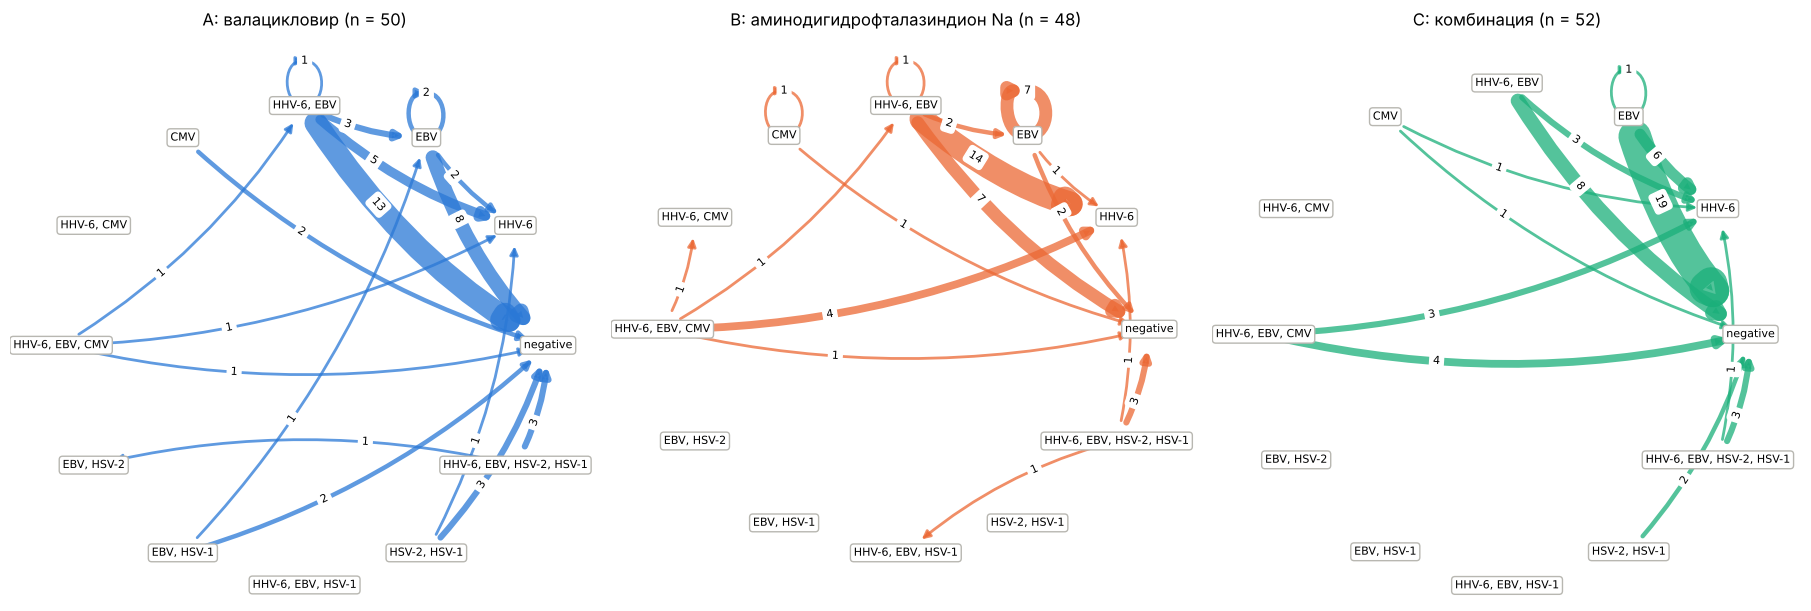

In [7]:
states = sorted(set(df["source"]) | set(df["target"]))
layout = nx.circular_layout(states)
fig, axes = plt.subplots(1, 3, figsize=(18, 6), constrained_layout=True)
for ax, group in zip(axes, "ABC"):
    counts = df[df["group"] == group].groupby(["source", "target"]).size()
    G = nx.DiGraph()
    G.add_nodes_from(states)
    G.add_weighted_edges_from((s, t, w) for (s, t), w in counts.items())
    widths = [0.8 + 1.2 * G[u][v]["weight"] for u, v in G.edges]
    nx.draw_networkx_edges(G, layout, ax=ax, width=widths, edge_color=GROUP_COLORS[group],
                           alpha=0.75, arrows=True, arrowsize=12,
                           connectionstyle="arc3,rad=0.12", node_size=900)
    nx.draw_networkx_edge_labels(G, layout, ax=ax, font_size=8, label_pos=0.35,
                                 edge_labels={(u, v): d["weight"] for u, v, d in G.edges(data=True)},
                                 connectionstyle="arc3,rad=0.12")
    nx.draw_networkx_labels(G, layout, ax=ax, labels={s: state_name(s) for s in states}, font_size=8,
                            bbox=dict(facecolor="white", edgecolor=NEUTRAL, boxstyle="round,pad=0.3"))
    ax.set_title(f"{GROUP_NAMES[group]} (n = {(df['group'] == group).sum()})")
    ax.set_axis_off()
plt.show()

## Часть 1. EVT: у кого состояние после лечения экстремально?

Graph-EVT-agent создан для многоканальных **временных рядов** `[время, канал]`: первые `baseline_size`
строк — «спокойный фон», по ним оцениваются медиана/MAD каждого канала и GPD-хвост агрегированного индикатора;
всё, что после фона, проверяется на превышение порога. У нас нет временной оси, поэтому делаем честное
перенесение смысла:

| Graph-EVT-agent | В этом ноутбуке |
|---|---|
| момент времени (строка) | пациент |
| канал | клинический показатель: `nf2` (t° на 14-й день), `nf3` (t° через 6 мес.), `nf1`, число вирусов в 1-е сутки |
| baseline (фон) | **калибровочная** часть пациентов, ставших ПЦР-отрицательными (55 из 83) |
| после фона | отложенные ответившие (контроль ложных тревог) + все неответившие |
| `top_k` | 2 — тревога требует отклонения минимум по двум показателям |
| `persistence` | 1 — порядок пациентов не является временем, «устойчивость во времени» не требуется |

Индикатор пациента — среднее двух наибольших робастных z-оценок `|x − median| / (1.4826·MAD)`.
Порог тревоги — квантиль GPD-хвоста с вероятностью превышения 5 % (`tail_quantile = 0.8`,
`alarm_probability = 0.95`). Так как часть показателей дискретна и у ответивших MAD бывает равен 0,
каналы предварительно делятся на своё стандартное отклонение в калибровочной группе, а `epsilon = 0.5`
ограничивает масштаб снизу половиной этого SD. Порог зависит **только** от калибровочных пациентов —
утечки нет.

Если калибровка корректна, то среди отложенных ответивших доля тревог должна быть около 5 %.

In [8]:
EVT_CHANNELS = ["nf2", "nf3", "nf1", "n_viruses_d1"]
EVT_CONFIG = EVTConfig(baseline_size=55, tail_quantile=0.8, alarm_probability=0.95,
                       top_k=2, persistence=1, epsilon=0.5)
responders = df.index[df["pcr_negative_6m"]].to_numpy()
non_responders = df.index[~df["pcr_negative_6m"]].to_numpy()


def evt_split(seed: int):
    """Калибровка на 55 ответивших, оценка на остальных пациентах."""
    rng = np.random.default_rng(seed)
    shuffled = rng.permutation(responders)
    calibration, held_out = shuffled[:EVT_CONFIG.baseline_size], shuffled[EVT_CONFIG.baseline_size:]
    order = np.concatenate([calibration, held_out, non_responders])
    values = df.loc[order, EVT_CHANNELS].to_numpy(float)
    values = values / values[:EVT_CONFIG.baseline_size].std(axis=0)
    detection = detect(values, EVT_CONFIG)
    flags = pd.Series(detection.indicator > detection.alarm_threshold, index=order)
    return detection, order, flags, calibration, held_out


detection, order, flags, calibration, held_out = evt_split(SEED)
print(f"Порог GPD: {detection.alarm_threshold:.2f}")
print(f"Тревоги среди отложенных ответивших: {flags[held_out].mean():.0%} (n = {len(held_out)})")
print(f"Тревоги среди неответивших:          {flags[non_responders].mean():.0%} (n = {len(non_responders)})")

Порог GPD: 5.59
Тревоги среди отложенных ответивших: 0% (n = 28)
Тревоги среди неответивших:          46% (n = 67)


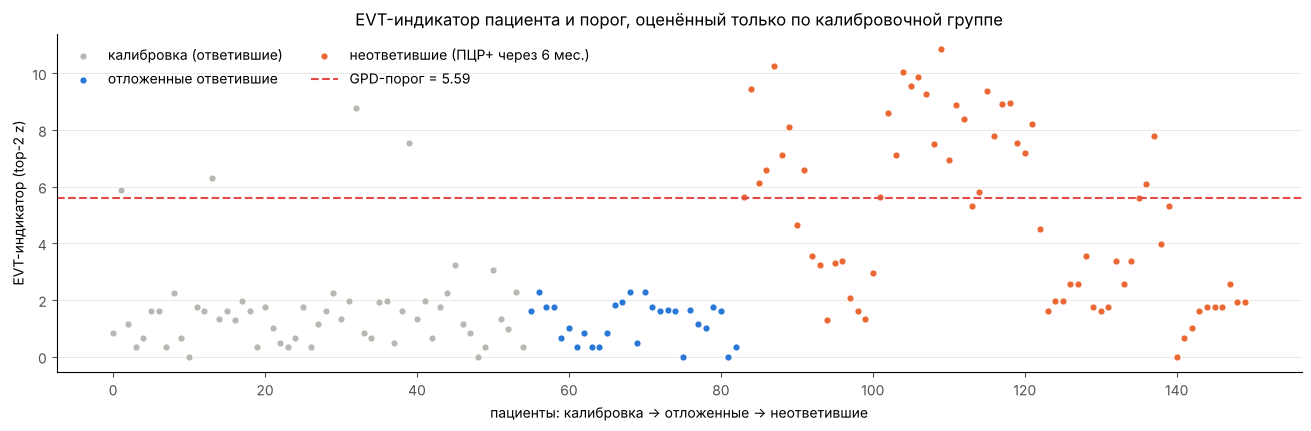

In [9]:
fig, ax = plt.subplots(figsize=(13, 4.2), constrained_layout=True)
position = np.arange(len(order))
segments = [("калибровка (ответившие)", slice(0, len(calibration)), NEUTRAL),
            ("отложенные ответившие", slice(len(calibration), len(calibration) + len(held_out)), "#2a78d6"),
            ("неответившие (ПЦР+ через 6 мес.)", slice(len(calibration) + len(held_out), None), "#eb6834")]
for label, part, color in segments:
    ax.scatter(position[part], detection.indicator[part], s=26, color=color, label=label,
               edgecolor="white", linewidth=0.6)
ax.axhline(detection.alarm_threshold, color=ALARM, linestyle="--", linewidth=1.5,
           label=f"GPD-порог = {detection.alarm_threshold:.2f}")
ax.set(xlabel="пациенты: калибровка → отложенные → неответившие", ylabel="EVT-индикатор (top-2 z)",
       title="EVT-индикатор пациента и порог, оценённый только по калибровочной группе")
ax.legend(frameon=False, ncol=2)
style(ax)
plt.show()

Одно случайное разбиение может быть удачным или неудачным, поэтому повторим калибровку 50 раз
с разными калибровочными подвыборками и усредним доли тревог.

In [10]:
rows = []
for seed in range(50):
    _, _, flags_s, _, held_s = evt_split(seed)
    row = {"отложенные ответившие": flags_s[held_s].mean(),
           "все неответившие": flags_s[non_responders].mean()}
    for group in "ABC":
        idx = non_responders[df.loc[non_responders, "group"].to_numpy() == group]
        row[f"неответившие {group}"] = flags_s[idx].mean()
    rows.append(row)
evt_summary = pd.DataFrame(rows).agg(["mean", "std"]).T
evt_summary.columns = ["доля тревог", "SD по разбиениям"]
evt_summary["n"] = [83 - EVT_CONFIG.baseline_size, len(non_responders)] + [
    int(((df["group"] == g) & ~df["pcr_negative_6m"]).sum()) for g in "ABC"]
evt_summary

,доля тревог,SD по разбиениям,n
отложенные ответившие,0.059,0.044,28
все неответившие,0.580,0.060,67
неответившие A,0.616,0.106,18
неответившие B,0.681,0.053,34
неответившие C,0.309,0.044,15


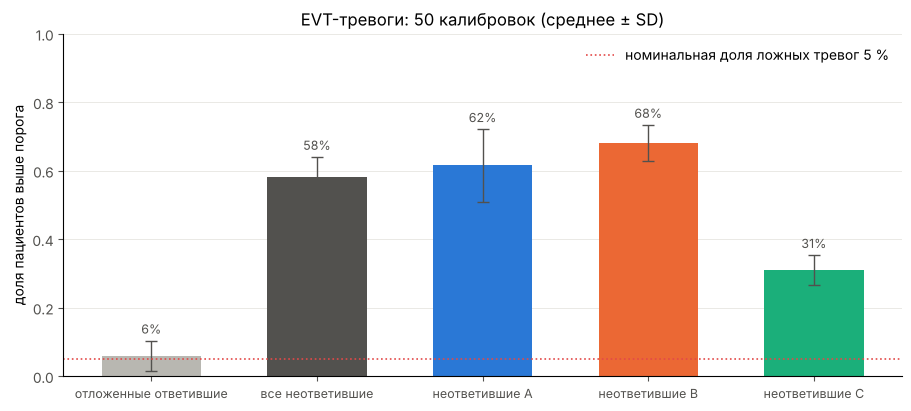

In [11]:
fig, ax = plt.subplots(figsize=(9, 4), constrained_layout=True)
colors = [NEUTRAL, MUTED, GROUP_COLORS["A"], GROUP_COLORS["B"], GROUP_COLORS["C"]]
bars = ax.bar(evt_summary.index, evt_summary["доля тревог"], yerr=evt_summary["SD по разбиениям"],
              color=colors, width=0.6, capsize=4, error_kw=dict(ecolor=MUTED, lw=1))
ax.bar_label(bars, labels=[f"{v:.0%}" for v in evt_summary["доля тревог"]], fontsize=9,
             color=MUTED, padding=3)
ax.axhline(1 - EVT_CONFIG.alarm_probability, color=ALARM, linestyle=":", linewidth=1.2,
           label="номинальная доля ложных тревог 5 %")
ax.set(ylabel="доля пациентов выше порога", ylim=(0, 1),
       title="EVT-тревоги: 50 калибровок (среднее ± SD)")
ax.tick_params(axis="x", labelsize=9)
ax.legend(frameon=False)
style(ax)
plt.show()

**Интерпретация.**

* Среди отложенных ответивших тревог около 5–7 % — калибровка GPD-порога согласуется с номиналом.
* У неответивших (ПЦР+ через 6 мес.) тревога срабатывает примерно у половины: их клиническое состояние
  выходит за пределы «нормального ответа», это и есть кандидаты на **терапевтический побег**, о котором
  говорит статья.
* Внутри неответивших доля экстремальных заметно ниже в группе C: даже если вирус сохранился,
  при комбинированной терапии клиника реже бывает экстремальной.

Ограничения: хвост GPD оценивается по 55 пациентам (≈ 11 превышений над квантилем 0.8), поэтому порог шумный —
отсюда разброс по разбиениям. EVT здесь — описательный инструмент, а не диагноз.

## Часть 2. Граф ко-инфекции вирусов

Graph-EVT-agent строит граф между каналами по фону с помощью AR-инноваций, DFA или вейвлет-фаз Курамото.
Все три метода требуют **упорядоченного во времени** сигнала, а строки нашей таблицы — разные пациенты,
отсортированные по группам. Поэтому граф строим так, как это корректно для поперечных данных:

* узлы — 5 вирусов;
* вес ребра — φ-корреляция (корреляция Пирсона бинарных признаков) наличия двух вирусов в 1-е сутки;
* ребро сохраняется, только если φ > 0 и перестановочный тест (999 перестановок) даёт p < 0.05.

Это тот же принцип, что и в библиотеке: «граф — гипотеза зависимости, проверенная против суррогатов».

In [12]:
def coinfection_graph(patients, n_perm: int = 999, seed: int = SEED, alpha: float = 0.05):
    """φ-корреляции наличия вирусов в 1-е сутки и перестановочные p-значения."""
    X = D1[np.asarray(patients)]
    phi = np.nan_to_num(np.corrcoef(X.T))
    rng = np.random.default_rng(seed)
    exceed = np.zeros_like(phi)
    for _ in range(n_perm):
        shuffled = np.column_stack([rng.permutation(X[:, j]) for j in range(X.shape[1])])
        exceed += np.abs(np.nan_to_num(np.corrcoef(shuffled.T))) >= np.abs(phi)
    p_value = (1 + exceed) / (n_perm + 1)
    adjacency = np.where((phi > 0) & (p_value < alpha), phi, 0.0)
    np.fill_diagonal(adjacency, 0.0)
    return phi, p_value, adjacency


phi, p_value, A_all = coinfection_graph(df.index)
co_counts = pd.DataFrame(D1.T @ D1, index=VIRUSES, columns=VIRUSES).astype(int)
print("Число пациентов с парой вирусов в 1-е сутки:")
display(co_counts)

Число пациентов с парой вирусов в 1-е сутки:


,HHV-6,EBV,CMV,HSV-2,HSV-1
HHV-6,87,87,17,13,13
EBV,87,138,17,13,16
CMV,17,17,23,0,0
HSV-2,13,13,0,19,19
HSV-1,13,16,0,19,22


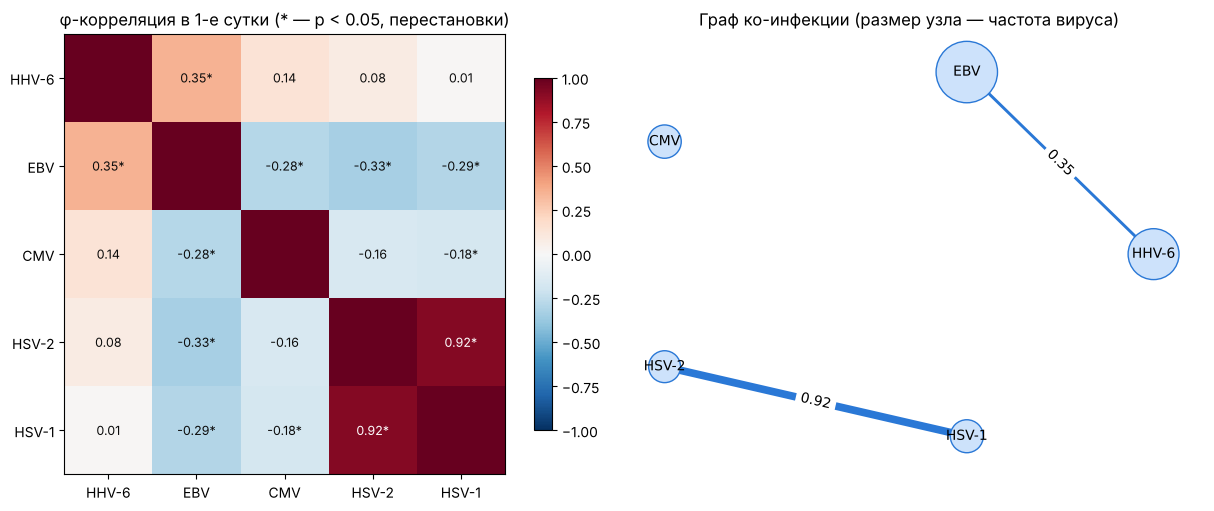

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)
ax = axes[0]
image = ax.imshow(phi, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(5), VIRUSES)
ax.set_yticks(range(5), VIRUSES)
for i in range(5):
    for j in range(5):
        if i != j:
            star = "*" if p_value[i, j] < 0.05 else ""
            ax.text(j, i, f"{phi[i, j]:.2f}{star}", ha="center", va="center", fontsize=9,
                    color="white" if abs(phi[i, j]) > 0.6 else "#0b0b0b")
ax.set_title("φ-корреляция в 1-е сутки (* — p < 0.05, перестановки)")
fig.colorbar(image, ax=ax, shrink=0.8)

ax = axes[1]
G = nx.Graph()
G.add_nodes_from(VIRUSES)
for i in range(5):
    for j in range(i + 1, 5):
        if A_all[i, j] > 0:
            G.add_edge(VIRUSES[i], VIRUSES[j], weight=round(A_all[i, j], 2))
pos = nx.circular_layout(G)
nx.draw_networkx_edges(G, pos, ax=ax, width=[6 * d["weight"] for _, _, d in G.edges(data=True)],
                       edge_color="#2a78d6")
nx.draw_networkx_edge_labels(G, pos, ax=ax, edge_labels=nx.get_edge_attributes(G, "weight"))
nx.draw_networkx_nodes(G, pos, ax=ax, node_size=[300 + 12 * n for n in D1.sum(axis=0)],
                       node_color="#cde2fb", edgecolors="#2a78d6")
nx.draw_networkx_labels(G, pos, ax=ax, font_size=10)
ax.set_title("Граф ко-инфекции (размер узла — частота вируса)")
ax.set_axis_off()
plt.show()

**Интерпретация.**

* **HHV-6 ↔ EBV** — значимая положительная связь: в этих данных HHV-6 *всегда* выявлялся вместе с EBV
  (87 из 87). Это согласуется с описанным в статье взаимным усилением HHV-6 и EBV (трансактивация промотора
  BZLF1/Zebra) и с ролью HHV-6 как «ключевого вторичного патогена».
* **HSV-1 ↔ HSV-2** — сильная связь: в данных эти вирусы почти всегда кодируются вместе.
* CMV значимых положительных связей не имеет; отрицательные φ у EBV с CMV/HSV — следствие того, что
  в таблице всего 7 разных исходных наборов вирусов, а не доказательство «антагонизма».

Цепочку EBV → HHV-6 → CMV из статьи эти 150 записей подтверждают лишь частично: ребро EBV–HHV-6 есть,
ребра HHV-6–CMV на уровне p < 0.05 нет (p ≈ 0.09).

## Часть 3. Graph-EVT-agent GNN/GAT: какой вирус сохранится через 6 месяцев?

`GraphProcessModel` из Graph-EVT-agent решает задачу «какой узел графа — источник события»:
на вход — эпизоды `GraphEpisode(features, adjacency, source)`, на выход — вероятность для каждого узла.
Переносим это на клиническую задачу:

* **эпизод** — один пациент;
* **граф** — 5 узлов-вирусов, рёбра — граф ко-инфекции из части 2 (замороженный, построен только на
  обучающих пациентах);
* **признаки узла** — какой это вирус (one-hot), выявлен ли он в 1-е сутки, сколько других вирусов выявлено,
  и признаки пациента: `nf1`, `edge_weights`, отклонение температуры на 14-й день, группа лечения;
* **метка (`source`)** — вирус, который остался через 6 месяцев.

Берём пациентов, у которых через 6 месяцев сохранился **ровно один** вирус (так метка однозначна).
`nf3` (температура через 6 мес.) **не используется** — она измерена одновременно с ответом.

Модель обучает сразу две сети на NumPy: **GNN** (свой признак + агрегаты соседей на 1 и 2 шага) и
**GAT** (обучаемое внимание по рёбрам, вес ребра — априорный множитель).

In [14]:
FEATURE_NAMES = ([f"узел={v}" for v in VIRUSES] + ["выявлен в 1 сутки", "других вирусов в 1 сутки",
                 "nf1", "edge_weights", "t° 14 день − 36.6", "группа A", "группа B", "группа C"])


def node_features(patient: int) -> np.ndarray:
    present = D1[patient]
    row = df.loc[patient]
    patient_level = np.array([row["nf1"], row["edge_weights"], row["nf2"] - 36.6]
                             + [float(row["group"] == g) for g in "ABC"])
    return np.column_stack([np.eye(5), present, present.sum() - present,
                            np.tile(patient_level, (5, 1))])


single = np.array([i for i in df.index if M6[i].sum() == 1])
labels = np.array([int(np.argmax(M6[i])) for i in single])
print(f"Пациентов с одним сохранившимся вирусом: {len(single)}")
print(pd.Series(np.array(VIRUSES)[labels]).value_counts().to_string())
pd.crosstab(df.loc[single, "group"].to_numpy(), np.array(VIRUSES)[labels],
            rownames=["группа"], colnames=["сохранился через 6 мес."])

Пациентов с одним сохранившимся вирусом: 60
HHV-6    43
EBV      16
CMV       1


сохранился через 6 мес.,CMV,EBV,HHV-6
группа,,,
A,0,6,9
B,1,9,20
C,0,1,14


Классы несбалансированы: HHV-6 остаётся примерно у 72 % таких пациентов. Поэтому главный ориентир —
**наивный базис «всегда HHV-6»**; модель полезна, только если превосходит его.

### Одно обучение: кривые качества и внимание GAT

Разбиение делаем функцией `split_episodes` из библиотеки (пациенты не попадают одновременно в train и
validation). Граф ко-инфекции строится только на пациентах, не попавших в validation.

train: 45 эпизодов, validation: 15 эпизодов (разбиение по: group)


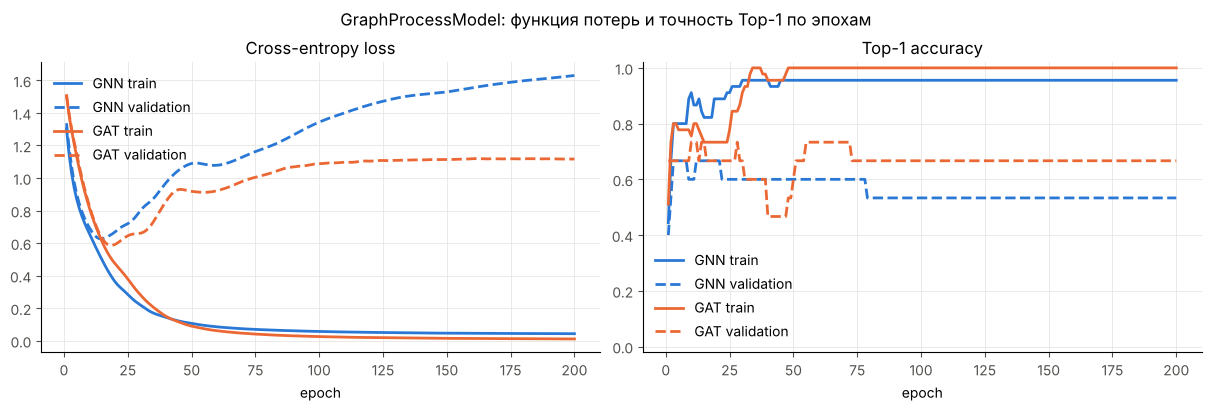

In [15]:
train_idx, val_idx, unit = split_episodes(list(single), groups=[str(p) for p in single],
                                          validation_fraction=0.25, random_state=SEED)
val_patients = set(single[val_idx])
graph_patients = [p for p in df.index if p not in val_patients]
_, _, A_train = coinfection_graph(graph_patients, n_perm=499)


def episodes(indices, adjacency):
    return [GraphEpisode(node_features(single[i]), adjacency, int(labels[i])) for i in indices]


train_eps, val_eps = episodes(train_idx, A_train), episodes(val_idx, A_train)
LEARNING = GraphLearningConfig(hidden_dim=8, epochs=200, learning_rate=0.02, l2=1e-3, random_state=SEED)
model = GraphProcessModel(LEARNING).fit(train_eps, validation=val_eps)
print(f"train: {len(train_eps)} эпизодов, validation: {len(val_eps)} эпизодов (разбиение по: {unit})")

fig = viz.plot_training_history(model.history_)
fig.suptitle("GraphProcessModel: функция потерь и точность Top-1 по эпохам")
plt.show()

Пациент #18: группа A, 1-е сутки: HHV-6, EBV, через 6 мес.: EBV


,GNN,GAT
HHV-6,0.52,0.12
EBV,0.48,0.88
CMV,0.00,0.00
HSV-2,0.00,0.00
HSV-1,0.00,0.00


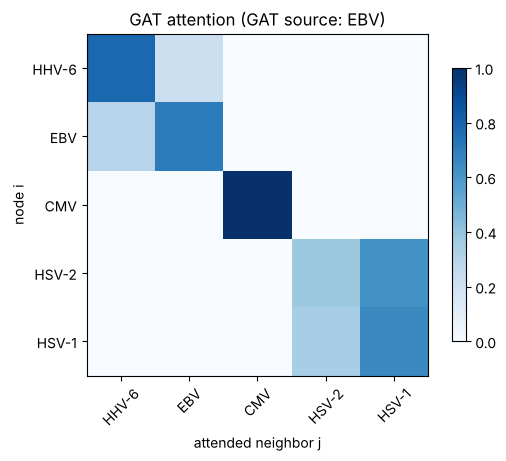

In [16]:
# Пример: пациент из validation с EBV + HHV-6 в 1-е сутки
example = next(single[i] for i in val_idx if D1[single[i], 0] and D1[single[i], 1])
prediction = model.predict(node_features(example), A_train)
row = df.loc[example]
print(f"Пациент #{example}: группа {row['group']}, 1-е сутки: {row['state_d1']}, "
      f"через 6 мес.: {row['state_6m']}")
display(pd.DataFrame({"GNN": prediction.gnn_probabilities, "GAT": prediction.gat_probabilities},
                     index=VIRUSES).style.format("{:.2f}").background_gradient(cmap="Blues", vmin=0, vmax=1))
fig = viz.plot_attention(prediction, VIRUSES)
plt.show()

Матрица внимания GAT — «граф процесса» конкретного пациента: строка `i` показывает, насколько узел `i`
опирается на себя и соседей. Внимание возможно только по рёбрам ко-инфекции, поэтому у HHV-6 и EBV
ненулевые веса друг на друга, а CMV опирается лишь на себя. Это **не** объяснение причинности —
это то, как модель взвесила информацию соседних узлов.

### Честная оценка: повторная стратифицированная кросс-валидация

60 эпизодов — мало, одно разбиение ненадёжно. Делаем 5-fold × 3 повтора. В каждом фолде:

1. граф ко-инфекции строится заново без пациентов тестового фолда;
2. сравниваем GNN и GAT с базисами:
   * **«всегда HHV-6»** — частоты классов на обучении;
   * **априорный ранжировщик** — частота сохранения вируса при его наличии/отсутствии в 1-е сутки (по обучению);
   * **GNN/GAT без графа** — та же модель с пустой матрицей смежности (абляция: даёт ли граф что-то).

Метрики из `graph_evt_agent.training.ranking_metrics`: Top-1, MRR, NLL (чем меньше, тем лучше калибровка).

In [17]:
from sklearn.model_selection import RepeatedStratifiedKFold

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)
strata = (labels == 0).astype(int)  # HHV-6 против остальных
scores = {name: [] for name in ["всегда HHV-6", "априорный ранжировщик", "GNN без графа",
                                 "GAT без графа", "GNN (граф ко-инфекции)", "GAT (граф ко-инфекции)"]}
EMPTY = np.zeros((5, 5))

for fold, (tr, te) in enumerate(cv.split(single, strata)):
    test_patients = set(single[te])
    _, _, A_fold = coinfection_graph([p for p in df.index if p not in test_patients], n_perm=199, seed=fold)
    truth = list(labels[te])

    frequency = np.bincount(labels[tr], minlength=5) + 0.5
    scores["всегда HHV-6"].append(ranking_metrics([frequency / frequency.sum()] * len(te), truth))

    prior = np.zeros((5, 2))
    for v in range(5):
        for state in (0, 1):
            mask = D1[single[tr], v] == state
            prior[v, state] = ((labels[tr][mask] == v).sum() + 0.5) / (mask.sum() + 1)
    prior_probs = []
    for p in single[te]:
        weights = prior[np.arange(5), D1[p].astype(int)]
        prior_probs.append(weights / weights.sum())
    scores["априорный ранжировщик"].append(ranking_metrics(prior_probs, truth))

    for adjacency, suffix in ((EMPTY, "без графа"), (A_fold, "(граф ко-инфекции)")):
        fitted = GraphProcessModel(LEARNING).fit(episodes(tr, adjacency))
        predictions = [fitted.predict(node_features(single[i]), adjacency) for i in te]
        scores[f"GNN {suffix}"].append(ranking_metrics([p.gnn_probabilities for p in predictions], truth))
        scores[f"GAT {suffix}"].append(ranking_metrics([p.gat_probabilities for p in predictions], truth))

cv_table = pd.DataFrame({
    name: {"Top-1": np.mean([m.top1 for m in ms]), "Top-1 SD": np.std([m.top1 for m in ms]),
           "MRR": np.mean([m.mrr for m in ms]), "NLL": np.mean([m.nll for m in ms])}
    for name, ms in scores.items()}).T
cv_table

,Top-1,Top-1 SD,MRR,NLL
всегда HHV-6,0.717,0.041,0.856,0.700
априорный ранжировщик,0.717,0.041,0.856,0.655
GNN без графа,0.822,0.096,0.911,0.567
GAT без графа,0.839,0.098,0.918,0.587
GNN (граф ко-инфекции),0.772,0.103,0.885,0.670
GAT (граф ко-инфекции),0.822,0.105,0.908,0.623


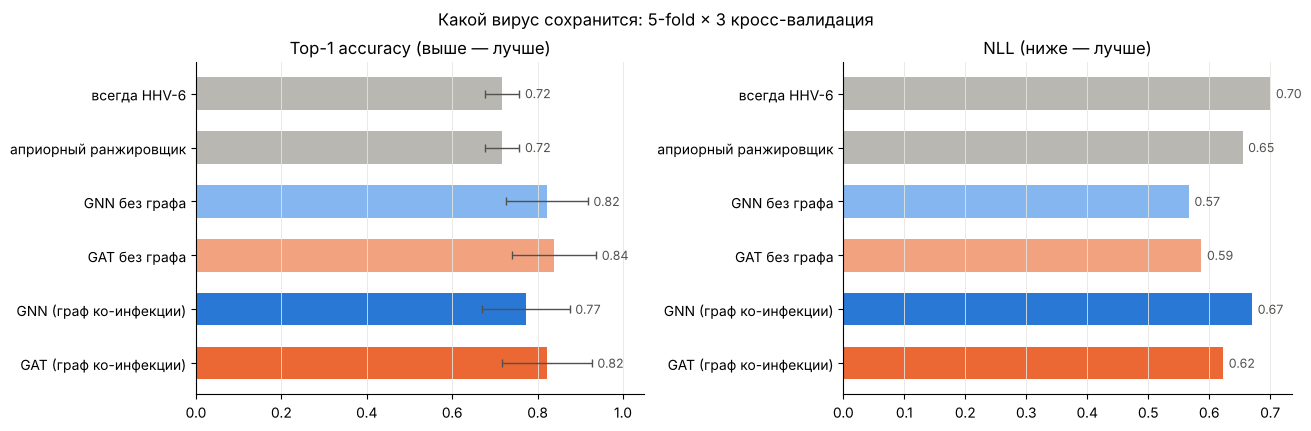

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), constrained_layout=True)
palette = [NEUTRAL, NEUTRAL, "#86b6ef", "#f2a27f", "#2a78d6", "#eb6834"]
for ax, metric, title in ((axes[0], "Top-1", "Top-1 accuracy (выше — лучше)"),
                          (axes[1], "NLL", "NLL (ниже — лучше)")):
    error = cv_table["Top-1 SD"] if metric == "Top-1" else None
    bars = ax.barh(cv_table.index, cv_table[metric], xerr=error, color=palette, height=0.6,
                   error_kw=dict(ecolor=MUTED, lw=1, capsize=3))
    ax.bar_label(bars, labels=[f"{v:.2f}" for v in cv_table[metric]], fontsize=9, color=MUTED, padding=4)
    ax.invert_yaxis()
    ax.set_title(title)
    ax.grid(True, axis="x", color="#e6e5e0", linewidth=0.6)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
axes[0].set_xlim(0, 1.05)
fig.suptitle("Какой вирус сохранится: 5-fold × 3 кросс-валидация")
plt.show()

**Интерпретация части 3** — см. таблицу выше:

* GNN и GAT Graph-EVT-agent превосходят базис «всегда HHV-6» (Top-1 ≈ 0.77–0.84 против 0.72, NLL ниже):
  модель не просто угадывает частый класс, а отличает пациентов, у которых сохранится EBV.
* Сигнал дают признаки узла — какой это вирус, был ли он в 1-е сутки и схема лечения. Из таблицы выше:
  при комбинированной терапии (C) EBV сохранился у 1 из 15, в группах A и B — у 6 из 15 и 9 из 30.
* **Граф ко-инфекции не помогает**: версии «без графа» не хуже, а то и лучше версий с графом. При 5 узлах и
  двух рёбрах соседи почти не добавляют информации, а агрегирование лишь размывает признаки узла.
  Это честный отрицательный результат абляции — ровно то, что README Graph-EVT-agent рекомендует проверять
  перед тем, как доверять GNN/GAT.
* SD по фолдам велико: в тестовом фолде всего 12 пациентов. Нужны внешние данные.

## Часть 4. PyTorch Geometric: будет ли ПЦР отрицательной и какая схема лучше?

Это главный вопрос статьи — эффективность схем лечения. Здесь узел — **пациент** (150 узлов), как в
исходном ноутбуке `GNN simple example Graph Convolution Network.ipynb`, но с исправленной согласованностью:
матрица признаков и граф описывают одни и те же 150 узлов.

* **Граф пациентов** — kNN (k = 6) по клиническому профилю. Группа лечения и исход в построение графа
  **не входят**.
* **Признаки узла** — профиль + one-hot группы лечения.
* **Цель** — ПЦР отрицательна через 6 месяцев (`target == 0`).
* **Модели** — GCN и GATv2 (как в исходном ноутбуке) и **логистическая регрессия** без графа как базис.
* 10 стратифицированных разбиений train/val/test (60/20/20), ранняя остановка по validation loss.

**Два варианта профиля.** Из описания статьи неясно, когда измерен `nf1` («агрегированный показатель
клинических проявлений»), а `nf2` — это температура на 14-й день, т. е. уже **во время** лечения. Если
показатель отражает ответ на лечение, то поправка на него «съедает» эффект схемы. Поэтому строим модели
дважды:

| Профиль | Признаки |
|---|---|
| **до лечения** | только 5 вирусов по ПЦР в 1-е сутки — заведомо измерены до лечения |
| **полный** | + `nf1`, `edge_weights`, t° 14-го дня |

In [19]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.neighbors import kneighbors_graph
from torch_geometric.nn import GATv2Conv, GCNConv

PROFILES = {
    "до лечения": D1,
    "полный": np.column_stack([D1, df["nf1"], df["edge_weights"], df["nf2"] - 36.6]),
}
therapy = np.eye(3)[df["class"].to_numpy() - 1]
y_np = df["pcr_negative_6m"].astype(int).to_numpy()
y = torch.tensor(y_np)


def patient_graph(profile: np.ndarray, k: int = 6):
    """Признаки узлов (z-профиль + схема лечения) и kNN-граф по профилю без схемы и исхода."""
    profile_z = (profile - profile.mean(axis=0)) / profile.std(axis=0)
    # Небольшой шум разрывает связи между пациентами с одинаковым профилем
    jitter = np.random.default_rng(SEED).normal(0, 1e-3, profile_z.shape)
    knn = kneighbors_graph(profile_z + jitter, n_neighbors=k, include_self=False)
    knn = ((knn + knn.T) > 0).astype(int).tocoo()
    edges = torch.tensor(np.vstack([knn.row, knn.col]), dtype=torch.long)
    return np.column_stack([profile_z, therapy]), edges, knn


for name, profile in PROFILES.items():
    X_np, edges, knn = patient_graph(profile)
    print(f"Профиль «{name}»: узлов {len(X_np)}, рёбер {edges.shape[1] // 2}, признаков {X_np.shape[1]}, "
          f"гомофилия по исходу {(y_np[knn.row] == y_np[knn.col]).mean():.2f}")

Профиль «до лечения»: узлов 150, рёбер 608, признаков 8, гомофилия по исходу 0.52
Профиль «полный»: узлов 150, рёбер 562, признаков 11, гомофилия по исходу 0.66


In [20]:
class GCN(torch.nn.Module):
    """Graph Convolutional Network, бинарный исход."""

    def __init__(self, dim_in, dim_h):
        super().__init__()
        self.gcn1 = GCNConv(dim_in, dim_h)
        self.gcn2 = GCNConv(dim_h, 2)

    def forward(self, x, edge_index):
        h = F.dropout(x, p=0.3, training=self.training)
        h = torch.relu(self.gcn1(h, edge_index))
        h = F.dropout(h, p=0.3, training=self.training)
        return self.gcn2(h, edge_index)


class GAT(torch.nn.Module):
    """Graph Attention Network (GATv2), бинарный исход."""

    def __init__(self, dim_in, dim_h, heads=4):
        super().__init__()
        self.gat1 = GATv2Conv(dim_in, dim_h, heads=heads)
        self.gat2 = GATv2Conv(dim_h * heads, 2, heads=1)

    def forward(self, x, edge_index):
        h = F.dropout(x, p=0.3, training=self.training)
        h = F.elu(self.gat1(h, edge_index))
        h = F.dropout(h, p=0.3, training=self.training)
        return self.gat2(h, edge_index)


def train_node_model(model, x, edge_index, train_mask, val_mask, epochs=300):
    """Adam + ранняя остановка: возвращает веса с минимальной validation loss."""
    optimizer = torch.optim.Adam(model.parameters(), lr=0.01, weight_decay=5e-4)
    best_loss, best_state = np.inf, None
    for _ in range(epochs):
        model.train()
        optimizer.zero_grad()
        loss = F.cross_entropy(model(x, edge_index)[train_mask], y[train_mask])
        loss.backward()
        optimizer.step()
        model.eval()
        with torch.no_grad():
            val_loss = F.cross_entropy(model(x, edge_index)[val_mask], y[val_mask]).item()
        if val_loss < best_loss:
            best_loss, best_state = val_loss, {k: v.clone() for k, v in model.state_dict().items()}
    model.load_state_dict(best_state)
    return model.eval()


def p_negative(model, x, edge_index):
    with torch.no_grad():
        return F.softmax(model(x, edge_index), dim=1)[:, 1].numpy()


def with_therapy(features, group_index):
    """Копия признаков, где всем пациентам назначена одна схема (A=0, B=1, C=2)."""
    changed = features.copy() if isinstance(features, np.ndarray) else features.clone()
    changed[:, -3:] = 0
    changed[:, -3 + group_index] = 1
    return changed

In [21]:
def run_profile(profile: np.ndarray, n_splits: int = 10):
    """Метрики на test и сценарий «всем схема X» для логрегрессии, GCN и GAT."""
    X_np, edge_index, _ = patient_graph(profile)
    x = torch.tensor(X_np, dtype=torch.float32)
    metrics, whatif = [], []
    splitter = StratifiedShuffleSplit(n_splits=n_splits, test_size=0.2, random_state=SEED)
    for run, (train_val, test) in enumerate(splitter.split(X_np, y_np)):
        torch.manual_seed(run)
        inner = StratifiedShuffleSplit(n_splits=1, test_size=0.25, random_state=run)
        a, b = next(inner.split(X_np[train_val], y_np[train_val]))
        train, val = train_val[a], train_val[b]

        logreg = LogisticRegression(max_iter=1000).fit(X_np[train_val], y_np[train_val])
        p = logreg.predict_proba(X_np[test])[:, 1]
        row = {"Логистическая регрессия AUC": roc_auc_score(y_np[test], p),
               "Логистическая регрессия Acc": accuracy_score(y_np[test], p > 0.5)}
        scenario = {f"Логистическая регрессия {g}": logreg.predict_proba(with_therapy(X_np, i))[:, 1].mean()
                    for i, g in enumerate("ABC")}
        for name, net in (("GCN", GCN(x.shape[1], 16)), ("GAT", GAT(x.shape[1], 8))):
            net = train_node_model(net, x, edge_index, torch.tensor(train), torch.tensor(val))
            p = p_negative(net, x, edge_index)[test]
            row[f"{name} AUC"] = roc_auc_score(y_np[test], p)
            row[f"{name} Acc"] = accuracy_score(y_np[test], p > 0.5)
            for i, g in enumerate("ABC"):
                scenario[f"{name} {g}"] = p_negative(net, with_therapy(x, i), edge_index).mean()
        metrics.append(row)
        whatif.append(scenario)
    return pd.DataFrame(metrics), pd.DataFrame(whatif)


pyg_metrics, pyg_whatif = {}, {}
for name, profile in PROFILES.items():
    pyg_metrics[name], pyg_whatif[name] = run_profile(profile)

pyg_table = pd.concat({name: frame.agg(["mean", "std"]).T.rename(columns={"mean": "среднее", "std": "SD"})
                       for name, frame in pyg_metrics.items()}, axis=1)
pyg_table

до лечения         полный       
                               среднее     SD среднее     SD
Логистическая регрессия AUC      0.656  0.099   0.810  0.065
Логистическая регрессия Acc      0.657  0.093   0.730  0.078
GCN AUC                          0.562  0.095   0.772  0.061
GCN Acc                          0.563  0.060   0.697  0.058
GAT AUC                          0.562  0.081   0.794  0.069
GAT Acc                          0.557  0.050   0.723  0.057

**Качество прогноза исхода.** Сравните AUC GCN/GAT с логистической регрессией: на 150 пациентах граф
пациентов **не даёт выигрыша** над простой моделью. kNN-граф лишь сглаживает признаки соседей, а исход в
основном определяется собственными признаками пациента. Это важный учебный вывод: GNN оправдана тогда,
когда в графе есть информация, которой нет в признаках узла. Полный профиль предсказывает исход заметно лучше
профиля «до лечения» — но см. оговорку ниже.

### Сценарий «что если» — ядро цифрового двойника

Для каждой обученной модели назначаем **всем** пациентам одну и ту же схему (A, B или C), оставляя их
профиль, и усредняем предсказанную вероятность отрицательной ПЦР. Так группы сравниваются при одинаковом
наборе пациентов.

,A: валацикловир,B: аминодигидрофталазиндион Na,C: комбинация
Наблюдаемая доля,64%,29%,71%
Логистическая регрессия | до лечения,59%,34%,70%
GCN | до лечения,61%,42%,64%
GAT | до лечения,57%,37%,68%
Логистическая регрессия | полный,58%,54%,54%
GCN | полный,58%,47%,61%
GAT | полный,60%,45%,63%


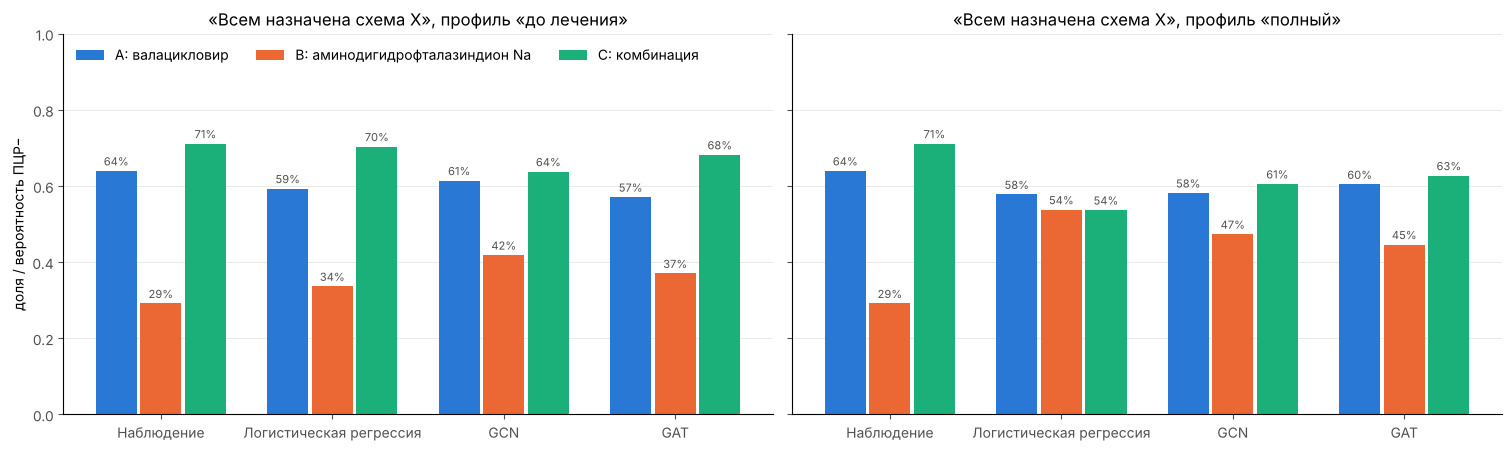

In [22]:
observed = df.groupby("group")["pcr_negative_6m"].mean()
MODELS = ["Логистическая регрессия", "GCN", "GAT"]
summary = {"Наблюдаемая доля": observed.to_numpy()}
for profile_name, frame in pyg_whatif.items():
    for model_name in MODELS:
        summary[f"{model_name} | {profile_name}"] = [frame[f"{model_name} {g}"].mean() for g in "ABC"]
summary = pd.DataFrame(summary, index=[GROUP_NAMES[g] for g in "ABC"]).T
display(summary.style.format("{:.0%}").background_gradient(cmap="Blues", axis=None, vmin=0, vmax=1))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.4), constrained_layout=True, sharey=True)
for ax, profile_name in zip(axes, PROFILES):
    rows = ["Наблюдаемая доля"] + [f"{m} | {profile_name}" for m in MODELS]
    positions = np.arange(len(rows))
    for k, group in enumerate("ABC"):
        values = summary.loc[rows].iloc[:, k].to_numpy()
        bars = ax.bar(positions + (k - 1) * 0.26, values, 0.24, color=GROUP_COLORS[group],
                      label=GROUP_NAMES[group])
        ax.bar_label(bars, labels=[f"{v:.0%}" for v in values], fontsize=8, color=MUTED, padding=2)
    ax.set_xticks(positions, ["Наблюдение"] + MODELS)
    ax.set(ylim=(0, 1), title=f"«Всем назначена схема X», профиль «{profile_name}»")
    style(ax)
axes[0].set_ylabel("доля / вероятность ПЦР−")
axes[0].legend(frameon=False, ncol=3, loc="upper left")
plt.show()

In [23]:
# Почему профили расходятся: nf1 сильно различается между группами и сильнее всего связан с исходом
confounding = df.groupby("group").agg(nf1_среднее=("nf1", "mean"), t14_среднее=("nf2", "mean"),
                                      ПЦР_отр=("pcr_negative_6m", "mean"))
confounding["corr(nf1, ПЦР−) по всем"] = np.corrcoef(df["nf1"], y_np)[0, 1]
confounding

,nf1_среднее,t14_среднее,ПЦР_отр,"corr(nf1, ПЦР−) по всем"
group,,,,
A,4.960,36.742,0.640,-0.619
B,9.458,36.988,0.292,-0.619
C,2.942,36.663,0.712,-0.619


**Интерпретация части 4.**

* **Профиль «до лечения»** (только вирусы в 1-е сутки): модели воспроизводят наблюдаемый порядок
  **C ≈ A > B** — комбинированная терапия и валацикловир заметно лучше монотерапии B. Это согласуется с
  выводом статьи.
* Но предсказательная сила профиля «до лечения» низкая (AUC логрегрессии ≈ 0.66, GCN/GAT ≈ 0.56 —
  близко к случайному), поэтому эти оценки грубые.
* **Полный профиль** (+ `nf1`, `edge_weights`, t° 14-го дня): различия между схемами резко сокращаются,
  у логистической регрессии почти исчезают (58 / 54 / 54 %).
  Причина — `nf1`: в группе B он в среднем в 3 раза выше, чем в группе C, и это самый сильный предиктор
  исхода. Модель объясняет плохой результат группы B высоким `nf1`, а не схемой лечения.
* **Какой вариант верен, зависит от смысла `nf1`.** Если это исходная тяжесть, измеренная до лечения, то
  группы изначально неравноценны, и преимущество C/A над B частично объясняется отбором пациентов. Если
  `nf1` (как и t° 14-го дня) отражает ответ на лечение, поправка на него недопустима (это медиатор), и
  правильный ответ — профиль «до лечения».
* Персональную «лучшую схему» по этим моделям давать нельзя: без взаимодействий «схема × профиль» аддитивная
  модель рекомендует всем одно и то же, а для взаимодействий 150 пациентов мало.

## Часть 5. Команда агентов (Mistral) — опционально

`EVTAgentTeam` из Graph-EVT-agent запускает собственный пайплайн по временному ряду, поэтому его нельзя
вызвать на поперечной таблице напрямую. Используем те же принципы: `MistralClient` из библиотеки
(повторы при 429/5xx, безопасные ошибки 401/403), роли «проверка данных → EVT → граф → обучение →
координатор», ограниченный JSON с итоговыми числами (без строк пациентов) и общий запрет менять численные
результаты.

Ключ задаётся через переменную окружения `MISTRAL_API_KEY` (в Colab — через *Secrets*). Без ключа ячейка
печатает сводку доказательств и пропускает LLM-шаг.

In [24]:
def as_float_dict(frame: pd.DataFrame) -> dict:
    frame = frame.copy()
    if isinstance(frame.columns, pd.MultiIndex):
        frame.columns = [" | ".join(map(str, column)) for column in frame.columns]
    return json.loads(frame.round(3).to_json(force_ascii=False))


evidence = {
    "data": {"patients": len(df), "groups": df["group"].value_counts().sort_index().to_dict(),
             "virus_prevalence": prevalence.to_dict(),
             "pcr_negative_share_by_group": observed.round(3).to_dict()},
    "evt": {"channels": EVT_CHANNELS, "baseline": "55 случайных ответивших (ПЦР− через 6 мес.)",
            "config": {"tail_quantile": EVT_CONFIG.tail_quantile,
                       "alarm_probability": EVT_CONFIG.alarm_probability, "top_k": EVT_CONFIG.top_k},
            "alarm_rates_50_splits": as_float_dict(evt_summary)},
    "coinfection_graph": {"edges": [[VIRUSES[i], VIRUSES[j], round(float(A_all[i, j]), 3)]
                                    for i in range(5) for j in range(i + 1, 5) if A_all[i, j] > 0],
                          "test": "phi > 0, перестановочный p < 0.05"},
    "persisting_virus_model": {"episodes": int(len(single)), "cv": "5-fold x 3",
                               "metrics": as_float_dict(cv_table)},
    "pcr_negative_model": {"metrics": as_float_dict(pyg_table),
                           "what_if_by_scheme": as_float_dict(summary),
                           "caveat": "профиль «полный» включает nf1 и t° 14-го дня; если это медиаторы "
                                     "ответа на лечение, корректен профиль «до лечения»"},
}
print(json.dumps(evidence, ensure_ascii=False, indent=1)[:3000])

{
 "data": {
  "patients": 150,
  "groups": {
   "A": 50,
   "B": 48,
   "C": 52
  },
  "virus_prevalence": {
   "1 сутки": {
    "HHV-6": 87,
    "EBV": 138,
    "CMV": 23,
    "HSV-2": 19,
    "HSV-1": 22
   },
   "6 месяцев": {
    "HHV-6": 49,
    "EBV": 22,
    "CMV": 2,
    "HSV-2": 1,
    "HSV-1": 1
   },
   "сохранился (из выявленных в 1 сутки)": {
    "HHV-6": 38,
    "EBV": 22,
    "CMV": 2,
    "HSV-2": 1,
    "HSV-1": 1
   },
   "впервые выявлен к 6 мес.": {
    "HHV-6": 11,
    "EBV": 0,
    "CMV": 0,
    "HSV-2": 0,
    "HSV-1": 0
   }
  },
  "pcr_negative_share_by_group": {
   "A": 0.64,
   "B": 0.292,
   "C": 0.712
  }
 },
 "evt": {
  "channels": [
   "nf2",
   "nf3",
   "nf1",
   "n_viruses_d1"
  ],
  "baseline": "55 случайных ответивших (ПЦР− через 6 мес.)",
  "config": {
   "tail_quantile": 0.8,
   "alarm_probability": 0.95,
   "top_k": 2
  },
  "alarm_rates_50_splits": {
   "доля тревог": {
    "отложенные ответившие": 0.059,
    "все неответившие": 0.58,
    "неотв

In [25]:
from graph_evt_agent.agents import MistralAPIError, MistralClient

try:  # Colab Secrets → переменная окружения (если доступно)
    from google.colab import userdata
    os.environ.setdefault("MISTRAL_API_KEY", userdata.get("MISTRAL_API_KEY") or "")
except Exception:
    pass

GUARD = ("Опирайся только на JSON. Не изменяй численные результаты. Отделяй статистическую "
         "редкость и ассоциацию от причинности, явно отмечай ограничения. Пиши по-русски кратко.")
ROLES = [
    ("Проверка данных", "Ты агент проверки клинических данных.",
     "Оцени объём выборки, баланс групп и риски утечки.", ["data"]),
    ("EVT", "Ты агент EVT-детекции.",
     "Объясни, откалиброван ли порог и что означают тревоги по группам.", ["data", "evt"]),
    ("Граф", "Ты агент графовых зависимостей.",
     "Объясни граф ко-инфекции и его связь с гипотезами статьи (EBV, HHV-6).", ["coinfection_graph"]),
    ("Обучение", "Ты агент оценки GNN/GAT-моделей.",
     "Сравни модели с базисами и оцени сценарий «что если».",
     ["persisting_virus_model", "pcr_negative_model"]),
]

if os.environ.get("MISTRAL_API_KEY"):
    try:
        client = MistralClient(model="mistral-small-latest")
        reviews = {}
        for title, system, task, keys in ROLES:
            payload = json.dumps({k: evidence[k] for k in keys}, ensure_ascii=False)
            reviews[title] = client.complete(f"{system} {GUARD}", f"{task}\nДанные: {payload}")
            print(f"### {title}\n{reviews[title]}\n")
        final = client.complete(
            f"Ты координатор команды цифрового двойника ХТФ. {GUARD}",
            "Составь итог для врача-исследователя: 5–7 пунктов и раздел «Ограничения». "
            f"Числа: {json.dumps(evidence, ensure_ascii=False)}\nОтзывы: {json.dumps(reviews, ensure_ascii=False)}")
        print("### Итог координатора\n" + final)
    except MistralAPIError as error:
        print(error)
else:
    print("MISTRAL_API_KEY не задан — LLM-обзор пропущен. Численные результаты выше от этого не зависят.")

MISTRAL_API_KEY не задан — LLM-обзор пропущен. Численные результаты выше от этого не зависят.


## Выводы

1. **Данные.** Коды `source`/`target` — битовая маска пяти герпесвирусов; после расшифровки виден главный
   факт: EBV доминирует в начале, а через 6 месяцев чаще остаётся HHV-6.
2. **EVT (Graph-EVT-agent).** GPD-порог, откалиброванный только на ответивших, держит долю ложных тревог
   около номинала и отмечает примерно половину неответивших как клинически экстремальных
   («терапевтический побег»); в группе C таких меньше.
3. **Граф ко-инфекции.** Значимы связи HHV-6–EBV и HSV-1–HSV-2; это частично поддерживает гипотезу статьи
   о связке EBV/HHV-6, но не всю цепочку EBV → HHV-6 → CMV.
4. **GNN/GAT Graph-EVT-agent.** Предсказывают сохраняющийся вирус лучше наивного базиса, но абляция
   показывает, что граф ко-инфекции к этому ничего не добавляет — работают признаки узла.
5. **PyG GCN/GAT.** Прогноз отрицательной ПЦР не лучше логистической регрессии. Сценарий «что если» по
   профилю «до лечения» ранжирует схемы как C ≈ A > B; при поправке на `nf1` и t° 14-го дня различия
   почти исчезают. Вывод об эффективности схем зависит от того, измерен ли `nf1` до лечения.

**Ограничения.** n = 150 и 60 эпизодов для части 3; нерандомизированные группы; время измерения `nf1` и
`edge_weights` известно только по описанию статьи (они используются и в части 3); рёбра и внимание GAT —
ассоциации, а не причинность. Для клинических выводов нужна внешняя валидация на независимой когорте.

**Ссылки.** Graph-EVT-agent: <https://github.com/D2718281828nis/Graph-EVT-agent> ·
исходный пример: `GNN simple example Graph Convolution Network.ipynb` · данные: `test_datasets/data_HTF.csv`.